## What to submit

There are some places to fill out in this notebook (we recommend creating a copy of it first).
These places are marked with `# FILL THIS`
There is also questions.txt file, which you should fill out, with some other questions (if you really need to and want to add some drawing, you can submit pdf version of it).

If you do not finish the last task (about papermill), you should submit the following:
This notebook (with filled output, i. e., processed via `restart and run all`) + `questions.pdf`.

If you do finish the last task, you should submit the following:
Clean notebook without outputs, all three options run via papermill and `questions.pdf`.

Submit separate files into subtasks.

## How to run Jupyter

You will be working in Jupyter notebook.
You can either run it locally (recommended) or use Google Colab (https://colab.research.google.com/) or Kaggle notebooks (https://www.kaggle.com/code). 

To run jupyter locally use `pip install jupyter` (I strongly recommends running `pip install jupyter --dry-run` first to check whether it will mess your environment) and then run `jupyter notebook`. 

## General comments

There are some new tools used in this exercise.
If you are stuck, it is recommendeded to run them on some small examples and inputs.

In [1]:
import numpy as np
import scipy.optimize
import scipy.stats
import matplotlib.pyplot as plt

In [2]:
# This is our dataset for regression task
# X are inputs and y are expected outputs
X,y=(np.array([[-0.87807714,2.7484093,-0.78545998],[2.87652638,1.00986944,0.44092245],[-0.41935993,2.09782686,2.76495212],[0.15410421,0.09975337,-0.38053507],[2.61289546,0.58528275,1.08075223],[1.95711634,2.6629513,1.51225777],[0.66424211,0.07598373,-0.22425579],[2.65815641,1.00910547,-0.60069576],[-0.55947245,0.78385802,1.23233958],[-0.63450607,2.6910434,0.09665965],[2.68706943,2.95792368,1.81771185],[-0.19447049,-0.32207179,1.14162893],[2.46667848,-0.62511065,1.20376062],[1.3768409,-0.94484484,0.81708307],[0.98856245,1.5235249,2.87987824],[2.22337675,1.27249015,1.50759574],[2.01528876,1.96707632,1.12547359],[1.83682073,-0.14230846,0.8295888],[-0.71651474,1.18625587,0.2561596],[2.11265703,1.4732835,2.43417396],[-0.1297147,-0.54556433,1.22140786],[0.95968638,0.07364526,1.6490482],[0.53832574,2.17600685,-0.16868996],[2.18901769,0.65975976,2.27862841],[-0.1649823,1.98662349,-0.26996464],[2.47526366,0.85816132,1.4030425],[0.05048938,-0.45457418,2.55159642],[2.10081494,1.2692753,2.49536845],[2.94027375,1.08932963,0.43143441],[1.8813987,0.1590138,0.3800428],[2.97235821,-0.59336797,1.24071169],[-0.58625245,1.90320281,1.33997433],[-0.89693084,2.91031968,-0.70125028],[0.32761796,0.01375456,2.88850148],[2.1703317,-0.15299766,0.77687499],[2.26409409,-0.59704405,-0.01600329],[2.27375672,-0.99115488,1.84786384],[2.87209754,1.53067711,1.77515573],[1.95551435,0.41280543,1.2878237],[-0.28136965,2.89236078,0.15392164],[0.14530631,0.17286559,0.49903255],[2.05174202,1.98812829,0.91954345],[0.15812157,-0.60528484,-0.44519224],[-0.69097057,2.1049133,2.973939],[1.79134534,-0.46124132,-0.30228918],[1.27911685,-0.62886025,0.1991696],[0.73647904,0.60655198,2.25655456],[-0.19480213,1.94594646,0.8908289],[0.67809385,0.7980378,1.40029275],[0.30909643,0.5185761,-0.42331497],[-0.7649619,1.625727,0.6126121],[2.57435862,0.70575912,-0.99388985],[-0.63891216,-0.99474501,1.44558121],[1.30510667,2.36333225,1.75893574],[0.42842064,-0.46677393,0.3766374],[0.381303,2.19389308,2.197326],[2.77004869,0.18030602,0.06114457],[0.5760142,2.69855504,1.80131147],[1.92002776,1.86147715,0.67874056],[0.83709434,0.90113975,-0.20399632],[2.13185882,-0.86044413,0.36345524],[2.63705292,2.33592012,0.46111007],[1.57449082,-0.07262557,1.94364557],[2.3961376,0.58266689,-0.79629331],[-0.01510533,-0.44323021,1.46479257],[-0.78347343,1.85293118,2.43835653],[1.15580321,2.31449927,-0.04533635],[2.75657454,2.22355575,2.6419257],[-0.11596114,-0.53217505,-0.3257638],[-0.38826476,1.52618699,1.94038295],[0.4432673,-0.31234227,2.5639046],[1.57903352,-0.24109136,-0.29163156],[-0.66411695,2.63022402,0.42787521],[1.38308022,-0.7627669,0.7621937],[2.51186308,-0.66498856,0.83964357],[2.61816274,-0.08796747,2.83852055],[0.57794241,0.76335057,2.21937798],[-0.72039009,-0.40491474,2.91494412],[2.18339761,0.35972451,2.37127035],[-0.39558813,-0.81438695,-0.91157096],[-0.365652,1.14724886,1.98081547],[-0.87552593,0.04574107,1.94676252],[-0.98701055,-0.98477953,-0.50807219],[1.51169138,0.76419538,2.43598707],[2.08856519,2.99055715,-0.98422436],[-0.65171983,0.60816876,2.13404224],[0.06948965,2.64023286,1.35159357],[1.07351113,2.7251514,0.6516931],[2.16388955,-0.81187043,0.88526536],[1.81854683,-0.90700445,1.36309377],[0.91403566,1.98098021,1.7724199],[1.12561821,2.24947655,1.27404174],[0.2623213,0.76556174,-0.48696893],[0.53062776,2.5363461,1.58821796],[-0.30323239,0.66348704,1.25279501],[-0.26385078,0.96850264,-0.27791463],[0.0413957,1.36711926,0.71154578],[-0.6693276,-0.47067029,2.50712504],[2.96743498,0.09930578,1.92609126],[2.23036736,-0.84423616,1.16271381],[1.99260565,-0.69237303,0.75347434],[0.38494847,1.23358656,0.16547543],[0.35818802,1.38465786,0.70666959],[0.30488969,0.69613165,2.44116738],[2.19576836,0.86162052,-0.50277746],[0.85601673,-0.75687874,0.28937407],[0.63733638,2.97596951,0.21306717],[-0.64659942,1.34754848,2.32515009],[0.94537075,0.85236101,2.20791302],[2.8120216,-0.34702894,0.0400638],[2.99271788,2.91295022,2.47815833],[2.77539827,-0.96715559,-0.24869245],[-0.197055,-0.13685877,1.22872493],[-0.97459389,2.22058672,2.42420781],[1.31403326,-0.24545722,1.00036404],[2.63011874,-0.48141366,1.35264493],[-0.17598804,2.59692397,-0.29450964],[1.8549467,1.28000661,0.76626374],[2.70364657,0.64842629,0.09066827],[1.36384821,1.86695256,0.60194598],[2.66974508,2.10838773,0.025772],[2.5507703,-0.27817959,1.90177477],[-0.05398606,2.8156609,2.91988492],[0.08837766,-0.91682917,1.29350428],[1.73306447,1.17626439,0.34282092],[0.17132373,0.68874698,0.23523422],[1.77898142,-0.7736851,1.05619881],[1.70218441,2.65836971,-0.4598332],[1.11742472,2.20099499,1.74760873],[0.32700743,1.03835463,-0.16639133],[1.18904886,2.96464525,-0.42726477],[0.0656465,-0.16472887,2.47558406],[-0.3427626,-0.70706049,2.61441141],[2.50970442,-0.08755278,-0.92950089],[1.82242584,1.88755355,2.59816606],[0.31326547,-0.80385797,-0.54872406],[2.83075732,1.6243,2.02427311],[-0.21911765,2.22806938,1.83283299],[0.54017682,0.90868916,1.60275378],[1.06466043,0.426264,1.16233552],[0.70305331,1.17949933,2.77369385],[0.82121163,2.0863103,1.92279012],[-0.12397228,1.3641944,1.21845982],[1.70848494,1.04589889,1.29030588],[2.7731197,1.43325284,-0.332977],[1.32307238,-0.64054747,2.25522334],[1.58008251,0.70817988,-0.67457133],[0.8433992,1.91337575,0.98401836],[2.23479139,1.81325231,0.58245529],[0.58685685,0.34098545,1.62348757],[2.6894146,1.94657513,0.03082561],[1.24254881,1.46627593,2.10898942],[0.39465609,1.94294985,1.36845694],[2.04177838,-0.58501996,1.61161293],[0.0826781,-0.99645126,2.07191683],[1.54717423,-0.20702576,1.25098713],[-0.40366256,-0.97641653,2.21446918],[0.24242237,2.86775869,0.53162376],[1.1184734,-0.6147328,0.03165713],[-0.37665052,1.77623314,0.2443949],[2.6496034,-0.75506701,-0.15731107],[0.21021664,-0.20777471,2.76320169],[2.03169726,0.40630929,2.87364445],[-0.11580955,1.49111968,2.37034332],[-0.22725989,0.7386296,0.88946614],[2.59368847,0.82753682,-0.20802193],[1.70208123,1.04986008,-0.52410679],[2.41282109,1.08736217,0.99768885],[-0.64933927,-0.93867422,0.46332538],[1.94318331,2.61217639,2.76607669],[-0.95252508,0.61299066,1.30831299],[1.84738503,1.79675837,0.97801548],[0.53063217,-0.70115651,1.70909157],[1.67510533,1.88885443,2.40076809],[1.3945413,0.38200123,-0.35640456],[0.31817699,1.10953197,1.45426511],[0.69029393,2.83619077,0.65827664],[1.98555603,0.37277324,1.12840193],[0.38809793,2.23541607,-0.47219164],[0.75541627,1.62587653,0.71882137],[2.87010925,-0.18870259,1.84948036],[0.18164049,-0.75013612,-0.34514245],[2.89805257,-0.71491324,1.38876401],[2.09478801,2.82844745,-0.46623258],[-0.77955171,2.71624185,2.62491801],[0.31216016,-0.1172136,2.50741827],[2.19693707,1.28658969,0.84604846],[1.64777874,2.51628414,2.55028297],[1.60679455,1.36753368,2.66388416],[2.28010322,0.7664118,2.64568763],[1.89429973,1.1158468,0.65851281],[0.93664664,1.88620744,-0.5940462],[-0.30703485,-0.86912159,1.54025091],[0.91203231,2.20284401,1.39151153],[2.09532639,1.71603373,-0.00635124],[0.51343405,0.3972294,-0.22321112],[2.56906113,2.96964476,1.94499215],[1.57773177,2.59305507,-0.94714958],[2.50426014,-0.29905786,1.47348909],[-0.45800373,-0.10479545,2.42537415],[0.79966221,1.26227445,1.2700834],[2.33675348,2.4241766,2.37187809],[2.0048473,-0.10078102,0.1193579],[2.08669129,-0.85465383,2.37924723],[0.30430817,2.1879199,2.19463204],[0.39760992,1.26951571,-0.90332665],[-0.35759588,1.71402922,-0.83798509],[-0.20272839,-0.9982276,1.04329691],[2.4585887,0.55373535,0.9425086],[2.75107076,1.34841295,0.40628951],[0.74229132,-0.28440219,1.26211831],[2.23339743,0.12333496,2.01674641],[2.87839504,-0.5654136,-0.23750903],[1.33757636,-0.5622148,2.08026338],[-0.89083858,-0.52996738,0.74080293],[-0.04016431,1.79254977,2.63998967],[-0.45601202,2.86554634,-0.86410754],[1.68965472,-0.50739239,1.47160918],[-0.24309203,2.98090593,-0.32549568],[0.88386113,2.50178597,0.44942842],[-0.01244973,1.51389766,0.50674863],[1.9388454,2.03336277,-0.83158839],[-0.60096071,-0.97978649,2.89500887],[1.40359358,1.76331065,1.95202807],[0.60495468,0.71392011,0.06554174],[2.64205021,0.0912312,-0.53011881],[1.93942586,2.60480175,0.12783231],[0.60380968,0.62935843,-0.08267966],[2.96865955,0.98687987,1.18566106],[1.16659571,2.63306649,-0.29082038],[0.03476262,-0.77803565,0.76789275],[0.60092092,1.52891383,1.98907051],[1.83156615,0.39853485,2.10715201],[0.06764101,-0.75431073,1.93362498],[2.05340702,1.73669885,0.39404796],[-0.38787601,0.34301205,1.93170907],[-0.99300644,0.04539237,1.08924318],[1.37455006,2.35691396,2.01860403],[2.72918918,0.74138033,2.99124762],[2.55719091,2.89516668,-0.43199698],[-0.2419973,-0.86886644,1.52270952],[-0.66999512,1.8892615,0.78905708],[2.01012812,1.6430789,0.84352011],[1.0520076,1.19171006,0.43375867],[1.82700152,0.84802504,-0.04833176],[-0.6664472,-0.04412759,2.58138586],[1.57762615,1.39461248,-0.13446468],[0.15754021,-0.46203902,0.88711579],[2.89762249,2.12425257,-0.63968075],[0.12645294,0.68862467,0.34542695],[-0.54883348,2.71302218,1.34148438],[1.85382993,-0.74248679,2.25815649],[1.89329425,2.22450324,-0.20895424],[2.65695817,0.98166062,1.37287412],[1.22087,-0.47416292,0.36719872],[0.69452858,-0.90959911,0.51311492],[-0.77926097,1.28482887,2.17949422],[-0.36260258,1.35838612,2.12109811],[2.95427234,2.67725244,0.57434909],[2.07411297,-0.2011014,2.83988601],[2.85782875,2.73514877,1.99251801],[-0.17534201,1.812912,1.42735907],[-0.70303222,0.76051809,-0.93159377],[1.86230289,1.73513053,1.79911585],[2.46671621,1.71392127,1.2655466],[0.85876233,-0.35646729,1.84480509],[0.61097652,2.69450368,0.25332386],[1.70159956,1.61118494,2.62611244],[2.17786486,0.27274964,0.56576053],[2.45819592,1.94373571,2.69642663],[-0.0675919,2.88173862,2.59086443],[2.88017283,2.81759205,2.01695861],[2.15177531,2.20475924,0.94384914],[1.1732972,0.34809311,2.84855065],[2.92711682,0.42289808,2.48241166],[2.12251657,1.42786261,0.36132737],[0.30508652,-0.41242929,2.13086898],[0.60826515,-0.75175558,-0.82500867],[1.25221552,2.12412605,1.47078918],[2.00789466,-0.6755755,2.74464007],[2.89175539,-0.29515238,1.44135261],[-0.45380255,1.80035379,2.39276755],[0.01794394,1.90905597,2.87470924],[0.43689865,0.01464953,-0.75546525],[-0.68273507,2.73783425,2.47753067],[1.17783081,-0.93132185,0.53697512],[-0.86281574,-0.1094171,1.83424405],[-0.6363073,-0.67277361,1.99094028],[0.98964837,0.31381613,0.7071039],[1.48113246,-0.4305699,-0.67213803],[0.68136777,0.39681344,1.60237077],[0.40975817,0.24376774,-0.8949015],[0.97662163,0.27047705,2.18179863],[2.81341693,1.53619653,1.37901092],[0.93519437,-0.70940153,2.07489143],[-0.74345234,2.96271277,1.55887776],[-0.00590514,2.74489672,-0.79423872],[0.48928067,0.89277422,1.03022927],[1.42234857,0.00870561,0.64253707],[-0.59296274,1.45159902,0.67972572]]),np.array([12,0,9,1,0,1,0,1,3,14,1,0,0,0,1,0,1,0,10,1,1,1,0,0,2,0,2,0,0,0,1,2,20,1,0,0,1,1,0,2,1,1,2,14,0,1,1,5,2,0,3,0,1,3,0,3,1,2,0,2,0,1,0,0,0,10,2,1,0,5,0,0,5,0,0,0,0,1,0,1,4,3,2,0,0,4,10,1,0,0,4,0,6,4,5,1,5,1,0,0,0,1,3,0,0,0,6,5,1,0,0,0,0,14,0,0,5,0,0,2,0,0,10,0,0,2,0,0,2,1,1,3,0,0,4,0,0,7,2,0,2,8,3,2,0,0,0,0,0,1,0,1,2,0,0,0,0,7,0,3,0,2,0,5,7,0,0,1,1,0,4,1,3,3,0,1,2,0,4,1,0,0,0,0,13,1,0,2,0,0,0,0,2,2,0,0,0,1,0,10,4,0,0,0,5,3,8,1,0,1,0,0,0,1,1,8,8,0,3,2,5,3,3,1,1,0,0,2,0,2,0,3,0,1,1,2,5,2,0,0,2,13,0,2,0,4,0,0,1,1,16,0,0,1,0,1,6,4,0,0,0,2,4,1,0,0,4,0,0,3,13,0,0,1,0,0,1,0,1,0,0,7,6,0,18,1,5,1,0,0,0,0,0,0,1,18,4,1,0,6]))

# We can check their shapes and see, that we have 300 samples with 3 attributes
X.shape, y.shape

((300, 3), (300,))

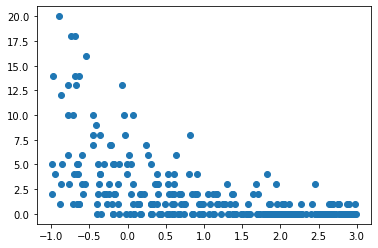

In [4]:
plt.scatter(X[:,0], y)

## Linear model

In [5]:
# Here is that typical way how to do linear regression without scikit-learn package
# (using scikit-learn is the recommended way, but here we want to dig slightly deeper).

# First we need to add one to input (so each sample changes from [a,b,c] for [a,b,c,1])
# Because linear model is y = t1*x1 + t2*x2 + t3*x3 + t0*1
X_and_one = np.concatenate([X, np.ones((X.shape[0], 1))], axis=1)

# Now we perform least squares fit (check out https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html)
coefs, _, _, _ = np.linalg.lstsq(X_and_one, y)
coefs

<ipython-input-5-047213d8820a>:9: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  coefs, _, _, _ = np.linalg.lstsq(X_and_one, y)


array([-1.61144395,  1.17433112,  0.3105525 ,  2.30421269])

In [6]:
# FILL THIS
# Here you should use scipy.optimize.minimize function (https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html)
# to find optimal fit for linear regression.
# This will fit the optimal parameters numerically. 
# To use it, you need to first create function which takes parameters of linear regression 
# (just parameters as one vector and nothing else)
# and outputs loss (sum or mean of squared errors). 
# You also need to specify starting point of optimization (this could be all zeroes). 
# Optionally (not needed here) you can also specify jac (function for getting derivative).
# Also do not forget to use X_and_one instead of X

# In short: find optimal parameters for linear regression using scipy.optimize.minimize

In [ ]:
# FILL THIS
# Calculate predictions (either from your numerical fit, or the first one) on X (aka X_and_one)

In [ ]:
# FILL THIS AND ALSO QUESTION 1 IN NOTES
# Show plot where predictions are on x-axis and true values (y) on y-axis

## Exponential model

In [ ]:
# As seen from chart above, the predictions are not great
# Maybe there is not a linear relation between variables
# We will change our model from y = Wx + Normal(.) to y = exp(Wx) + something
# Normal(.) just denotes normally distributed error, with unknown variance
# To fit it, we first logarithm everything so we get log(y) = Wx
# Let's name log(y) = y_log, and thus we fit y_log = Wx

# We need to add epsilon, since sometimes y is zero

epsilon = <your choice>
y_log = np.log(y+epsilon)

In [ ]:
# FILL THIS
# Find good parameters for model above
# Do not forget to work with X_and_one

In [ ]:
# FILL THIS AND ALSO QUESTION 2 IN NOTES
# Calculate predictions and plot them as above
# You should plot your predictions (after exp) against y

## Poisson model

In [7]:
# scipy.stats.poisson.pmf(sample, mean) gives you probability of drawing sample given mean
# scipy.stats.poisson.pmf([s1, s2], [m1, m2]) gives you probability of drawing s1 given m1 and s2 given m2

scipy.stats.poisson.pmf([0, 2], [1.5, 3.7])

array([0.22313016, 0.16923254])

In [ ]:
# FILL THIS
# Even exponential model is not ideal
# We will change our model again to y = Poisson(exp(Wx))
# I.e. we get x, multiple by W, calculate exp of it and then draw from Poission distribution with
# corresponding mean.

# Find good parameters for this model
# Probably you need to use scipy.optimize.minimize
# Your loss function should minimize negative (log) likehood of the fit (or some equivalent quantity)
# In other words you want to maximize "probability" of seeing y values.
# scipy.stats.poisson.pmf(sample, mean) gives you probability of drawing sample given mean
# scipy.stats.poisson.pmf([s1, s2], [m1, m2]) gives you probability of drawing s1 given m1 and s2 given m2
# 
# Do not forget to work with X_and_one



In [ ]:
# FILL THIS AND ALSO QUESTION 3 IN NOTES
# Calculate predictions and plot them as above
# You should plot your predictions (not samples from Poisson distribution, but just it's mean) against y


# Also calculate confidence interval of your predictions and visualize it for subset of predictions

## Make this parametrizable

In [ ]:
# FILL THIS
# Cleanup and parametrize this notebook and run all choices over papermill
# Check out https://github.com/nteract/papermill
# Ignore stuff about s3, you can just run `papermill input.ipynb output.ipynb -p par1 value1 -p par2 value2`
# If you cannot figure out how to alter cell tags in new versions of jupyter notebook, 
# you can install 'pip install nbclassic' and run 'jupyter nbclassic' from command line.

# Your notebook should have one parameter: model type
# This can be one of three choices
# A) Linear model
# B) Exp model
# C) Poisson model

# Given the choice, you notebook should:
# 1) Load data
# 2) Fit the relevant model
# 3) Calculate and show the predictions (and confidence interval for poisson model)